# Two GPUs: the 1D powder pattern of every frame, on one GPU and then on two

Dense integration: every pixel of every frame goes through pyFAI's sparse matrix, and no sparse
pixels are collected (integrate(chunks) of chunk2sparseCSC).  Each GPU has its own object
(device=0, device=1) driven by its own Python thread; the frames are split in two halves.  The
decoding and the matrix product run on the GPUs and the threads mostly wait for them, so two GPUs
should take about half the time of one, unless the host cannot feed them (copying the compressed
chunks into pinned memory, the uploads).  Each call's powder comes back to the host, as it would
for writing it out.  The chunks are read from the file once, before the clock starts, and passed
over several times so that each run takes long enough to time.  With one GPU, only the one-GPU
time is shown.

In [1]:
import os
import platform
import threading
import time

In [2]:
os.environ["BSLZ4_CUDA_BACKEND"] = "driver"  # set before bslz4_to_sparse.cuda is imported

In [3]:
import h5py
import hdf5plugin  # registers the bitshuffle filter, so that h5py can decompress too
import matplotlib.pyplot as plt
import numpy as np
import pyFAI
from pyFAI.method_registry import IntegrationMethod

from bslz4_to_sparse import cuda

In [4]:
h5filename = "eiger_0000.h5"  # your file: bitshuffle-lz4 (8 kB blocks), one frame per chunk
h5dataset = "/entry_0000/ESRF-ID11/eiger/data"  # the (nframes, ni, nj) dataset inside it
mask_filename = (
    "mask.h5"  # your detector mask: a dataset "mask", pyFAI's convention (non-zero = masked)
)
poni_filename = "calib.poni"  # your pyFAI geometry
frames_to_time = 10000  # the file's frames, passed over until there are this many
per_call = 128  # frames per integrate() call

In [5]:
with h5py.File(h5filename, "r") as h5:
    ds = h5[h5dataset]
    dtype = ds.dtype
    file_chunks = [ds.id.read_direct_chunk((i, 0, 0))[1] for i in range(ds.shape[0])]
    frame0 = ds[0]
with h5py.File(mask_filename, "r") as h5:
    bad = h5["mask"][()] != 0  # the masked pixels
mask = (~bad).astype(np.uint8)
passes = max(1, -(-frames_to_time // len(file_chunks)))
chunks = file_chunks * passes
print("%d frames of %s %s: the file's %d, %d times; %.1f MB compressed"
      % (len(chunks), frame0.shape, dtype, len(file_chunks), passes,
         sum(len(c) for c in chunks) / 1e6))

10000 frames of (2162, 2068) uint16: the file's 250, 40 times; 1496.2 MB compressed


In [6]:
ai = pyFAI.load(poni_filename)
method = IntegrationMethod.select_one_available(("bbox", "csc", "cython"), dim=1)
ref = ai.integrate1d(frame0, 1000, unit="q_nm^-1", method=method, mask=bad)
engine = ai.engines[method].engine

In [7]:
ngpu = min(2, cuda.device_count())
gpus = [cuda.chunk2sparseCSC(mask, engine, dtype, device=d) for d in range(ngpu)]
print("%s; GPUs: %s" % (platform.machine(),
                        ", ".join(cuda.device_name(d) for d in range(ngpu))))
for g in gpus:  # first calls: buffers allocated, kernels loaded
    g.integrate(chunks[:per_call])

ppc64le; GPUs: Tesla V100-SXM2-32GB, Tesla V100-SXM2-32GB


In [8]:
def integrate_on(devices):
    """Every frame's powder (host array) and the seconds it took, the frames split over devices."""
    parts = np.array_split(np.arange(len(chunks)), len(devices))
    out = [None] * len(devices)

    def work(k):
        g, idx = gpus[devices[k]], parts[k]
        out[k] = np.concatenate([
            g.integrate(chunks[idx[s]: idx[s] + len(idx[s: s + per_call])]).get()
            for s in range(0, len(idx), per_call)
        ])

    threads = [threading.Thread(target=work, args=(k,)) for k in range(len(devices))]
    t0 = time.perf_counter()
    for t in threads:
        t.start()
    for t in threads:
        t.join()
    return np.concatenate(out), time.perf_counter() - t0

In [9]:
powder1, t1 = integrate_on([0])
assert np.allclose(powder1[0], ref.sum_signal, rtol=1e-9, atol=0)  # pyFAI's sums for frame 0
rates = {"1 GPU": len(chunks) / t1}
print("1 GPU : %6.3f s, %6.0f frames/s" % (t1, rates["1 GPU"]))
if ngpu == 2:
    powder2, t2 = integrate_on([0, 1])
    assert np.array_equal(powder1, powder2)  # the same sums, bit for bit
    rates["2 GPUs"] = len(chunks) / t2
    print("2 GPUs: %6.3f s, %6.0f frames/s, %.2f times one GPU" % (t2, rates["2 GPUs"], t1 / t2))
else:
    print("one GPU here: no two-GPU run")

1 GPU :  1.432 s,   6985 frames/s


2 GPUs:  0.726 s,  13779 frames/s, 1.97 times one GPU


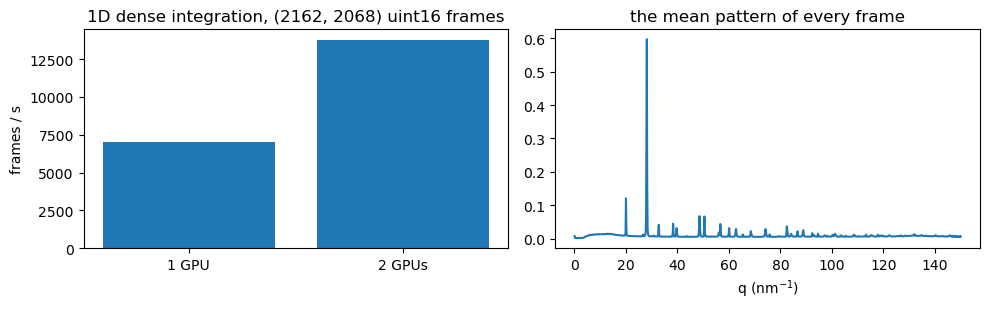

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(list(rates), list(rates.values()))
axes[0].set_ylabel("frames / s")
axes[0].set_title("1D dense integration, %s %s frames" % (frame0.shape, dtype))
norm = np.asarray(ai.integrate1d(np.ones(frame0.shape, np.float32), 1000, unit="q_nm^-1",
                                 method=method, mask=bad).sum_normalization)
axes[1].plot(ref.radial, powder1.mean(axis=0) / np.maximum(norm, 1e-30))
axes[1].set_xlabel("q (nm$^{-1}$)")
axes[1].set_title("the mean pattern of every frame")
plt.tight_layout()
plt.show()